# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Tumor Screening Dashboard

### Scenario

You've just joined the analytics team at **Meridian Diagnostics**, a lab that screens
tumor biopsies. Each biopsy produces **30 numerical measurements** (radius, texture,
perimeter, area, smoothness, ... in mean/SE/worst variants) — far too many to eyeball in
a spreadsheet. The lead pathologist has given you a blunt brief:

1. *"I can't look at 30 numbers per patient and see anything. I need to SEE the data."*
2. *"Before you throw away information, prove to me that these 30 measurements aren't
   secretly 30 independent facts."*
3. *"Build me a 2D map of every patient. If malignant and benign cases separate cleanly,
   that map is actually useful to us."*
4. *"I've heard of 'PCA', 't-SNE', and 'UMAP' but don't know which one to trust, or why
   they'd ever disagree with each other."*

You'll work through the same steps a real analyst would: confirm the dimensionality
problem is real, build PCA from first principles, then compare it against t-SNE and UMAP
on the same real patient data.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset you'll be working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

np.random.seed(0)

df = pd.read_csv("breast_cancer.csv")
df = df.drop(columns=["Unnamed: 32"], errors="ignore")
feature_cols = [c for c in df.columns if c not in ["id", "diagnosis"]]
X_raw = df[feature_cols].values
y = df["diagnosis"].values

print(f"Loaded {df.shape[0]} patients, {len(feature_cols)} measured dimensions.")
df[feature_cols[:5] + ["diagnosis"]].head()

Loaded 569 patients, 30 measured dimensions.


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,M
1,20.57,17.77,132.90,1326.0,0.08474,M
2,19.69,21.25,130.00,1203.0,0.10960,M
3,11.42,20.38,77.58,386.1,0.14250,M
4,20.29,14.34,135.10,1297.0,0.10030,M


## Task 1 — Prove the Dimensionality Problem Is Real (Complaint #1)

**Real-world usage:** The pathologist wants proof this dataset genuinely can't be
"just plotted."

**Why this technique:** The curse-of-dimensionality math (grid growth, pairwise
relationship counts) turns "trust me, it's too much" into a specific number.

**TODO:**
1. Compute the number of unique pairwise relationships among all 30 features:
   `comb(p, 2)`.
2. Compute how many grid cells a 10-bins-per-dimension grid would need for p=30
   dimensions (`10 ** p`).
3. Print both, with a one-line comment on what each number implies.

In [2]:
p = len(feature_cols)

# TODO 1: number of unique pairwise relationships among the 30 features
n_pairs = comb(p,2)

# TODO 2: number of grid cells for a 10-bin-per-dimension grid at p=30
n_cells = 10 ** p

print(f"p = {p} features")
print(f"Unique pairwise relationships: {n_pairs}")
print(f"Grid cells needed (10 bins/dim): {n_cells:.2e}" if n_cells else "Grid cells needed: (fill in above)")

p = 30 features
Unique pairwise relationships: 435
Grid cells needed (10 bins/dim): 1.00e+30


**Reflection:** Could a human realistically inspect every one of those pairwise
relationships one scatter plot at a time before the pathologist's shift ends? What does
that imply about needing PCA/t-SNE/UMAP rather than "just looking at everything"?

_Your answer:_ No, 435 pairwise scatter plots are already far too many for a person to inspect properly in one shift. And 10^30 grid cells is an unimaginably huge number, so looking at everything is not practical. This is the curse of dimensionality: as the number of dimensions increases, the number of relationships and possible combinations grows very quickly, while the amount of data stays the same. That is why we use PCA, t-SNE, or UMAP to reduce 30 dimensions to 2 or 3 that are easier to visualize, even if some information is lost.

## Task 2 — Prove the 30 Measurements Aren't Independent (Complaint #2)

**Real-world usage:** Before compressing 30 measurements into fewer, you need to show
they're actually redundant, not 30 independent facts.

**Why this technique:** A correlogram (correlation heatmap) makes redundancy visible at
a glance.

**TODO:**
1. Compute the correlation matrix of `df[feature_cols]`.
2. Plot it as a heatmap (`plt.imshow`, `cmap="RdBu_r"`, `vmin=-1, vmax=1`).
3. Count how many feature pairs have `abs(correlation) > 0.9` (excluding the diagonal).

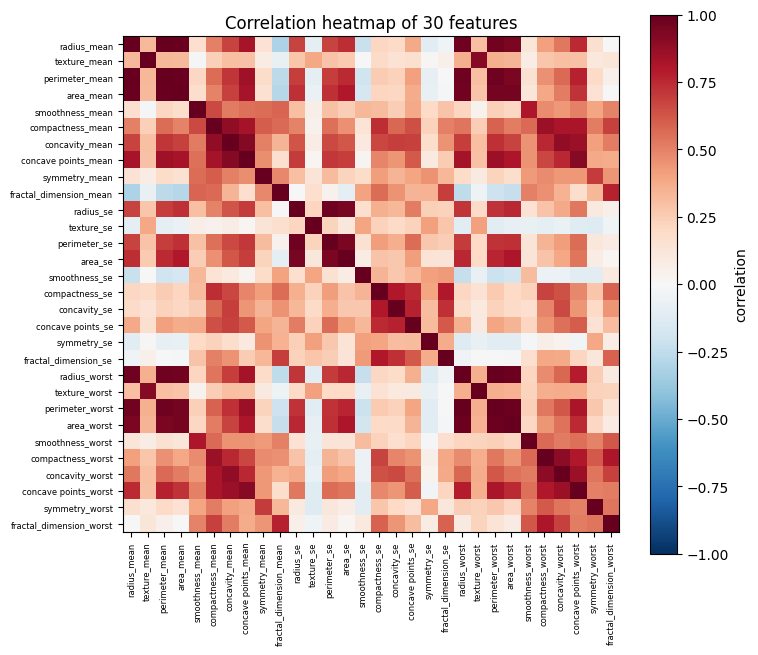

Highly correlated pairs (|r| > 0.9): 21


In [3]:
# TODO 1: correlation matrix
corr = df[feature_cols].corr()

fig, ax = plt.subplots(figsize=(8, 7))

# TODO 2: plot the heatmap
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)))
ax.set_yticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=90, fontsize=6)
ax.set_yticklabels(feature_cols, fontsize=6)
fig.colorbar(im, ax=ax, label="correlation")
ax.set_title("Correlation heatmap of 30 features")

plt.show()

# TODO 3: count highly correlated pairs (> 0.9 in magnitude, excluding self-correlation)
corr_abs = corr.abs()
mask = np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
high_corr_pairs = int((corr_abs.where(mask) > 0.9).sum().sum())
print("Highly correlated pairs (|r| > 0.9):", high_corr_pairs)

**Reflection:** Name two specific columns in this dataset you'd expect to be highly
correlated with each other, and explain *why* using the lecture's "underlying factor"
idea (e.g. tumor size).

_Your answer:_ radius_mean and perimeter_mean, or radius_mean and area_mean, are highly correlated because they all measure the same basic thing: tumor size. A bigger tumor naturally has a bigger radius, perimeter, and area. So these columns are not really three separate pieces of information, which is the kind of redundancy PCA is meant to reduce.

## Task 3 — Build PCA From Scratch (Complaint #3, part A)

**Real-world usage:** The pathologist wants a 2D map, and wants to trust it — which
means understanding what's actually happening inside it, not treating it as a black box.

**Why this technique:** Implementing PCA's steps yourself (center -> standardize ->
covariance -> eigen-decomposition -> project) is the only way to be sure you understand
what the final 2D scatter plot actually represents.

**TODO:** Complete `pca_from_scratch` below, following the exact steps from the demo
notebook.

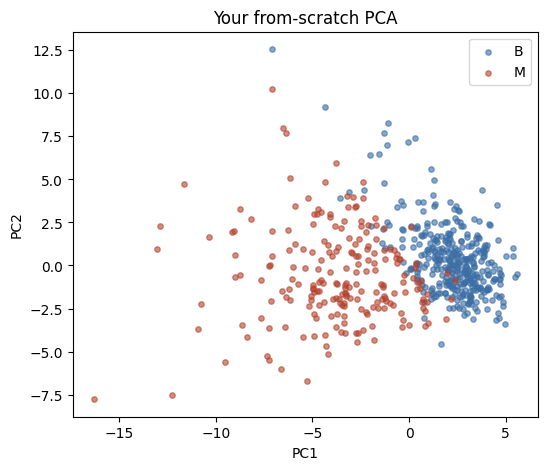

In [4]:
def pca_from_scratch(X, k):
    # TODO 1: center AND standardize X (subtract mean, divide by std with ddof=1)
    X_scaled = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

    # TODO 2: compute the covariance matrix of X_scaled
    cov = np.cov(X_scaled, rowvar=False)

    # TODO 3: eigen-decompose the covariance matrix, and sort eigenvalues/eigenvectors DESCENDING
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = np.argsort(eigvals)[::-1]
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    # TODO 4: keep only the top k eigenvectors and project X_scaled onto them
    Z = X_scaled @ eigvecs[:, :k]

    return Z, eigvals, eigvecs

Z, eigvals, eigvecs = pca_from_scratch(X_raw, k=2)

fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [("B", "#3b6ea5"), ("M", "#b5432e")]:
    mask = y == label
    ax.scatter(Z[mask, 0], Z[mask, 1], s=15, alpha=0.6, color=color, label=label)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("Your from-scratch PCA")
ax.legend()
plt.show()

**Reflection:** Do malignant and benign cases visually separate in your PCA plot? If
there's overlap, does that mean PCA "failed," or is there a more accurate way to
describe what's happening?

_Your answer:_ Yes, malignant and benign cases separate reasonably well along PC1, although there is still some overlap in the middle. This does not mean PCA failed because PCA does not use the diagnosis when finding the components. It only looks for directions with the most variance. In this case, tumor size and shape seem to be the main source of variation, and that happens to correlate fairly well with malignancy, although not perfectly.

## Task 4 — Choose k With Evidence, Not a Guess

**Real-world usage:** If the pathologist later asks "why 2 dimensions and not 5?", you
need a defensible answer.

**Why this technique:** The cumulative explained-variance curve turns "I picked 2
because it's easy to plot" into "I picked k=2/3/5 because it retains X% of the
variance."

**TODO:**
1. Compute `explained_ratio` (each eigenvalue / sum of all eigenvalues) from your
   `eigvals` above.
2. Compute the cumulative sum.
3. Find the smallest k that reaches >= 90% cumulative variance.

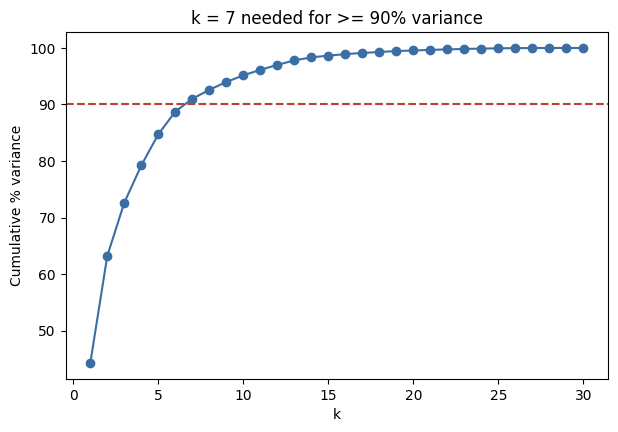

In [5]:
# TODO 1: explained variance ratio
explained_ratio = eigvals / eigvals.sum()

# TODO 2: cumulative variance
cumulative = np.cumsum(explained_ratio)

# TODO 3: smallest k reaching >= 90%
k_90 = int(np.argmax(cumulative >= 0.90) + 1)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, len(cumulative) + 1), cumulative * 100, "o-", color="#3b6ea5")
ax.axhline(90, color="#b5432e", ls="--")
ax.set_xlabel("k"); ax.set_ylabel("Cumulative % variance")
ax.set_title(f"k = {k_90} needed for >= 90% variance" if k_90 else "Choosing k")
plt.show()

**Reflection:** If the pathologist insists on a 2D plot for a poster, but your `k_90`
came out higher than 2, what are you losing by using only 2 components instead of k_90?

_Your answer:_ Using only 2 components means losing some of the variation captured by the other components. Two patients may look similar in the 2D plot but still differ in other features. This is fine for a poster because it improves readability, but the plot is only a simplified view and should not be used alone for diagnosis.

## Task 5 — Compare PCA, t-SNE, and UMAP (Complaint #4)

**Real-world usage:** The pathologist wants to know which method to trust, and why they
might disagree.

**Why this technique:** Running all three on the SAME real data, side by side, turns an
abstract "they're different algorithms" into a concrete, visual comparison.

**TODO:**
1. Standardize `X_raw` using `StandardScaler`.
2. Compute a 2D PCA embedding, a 2D t-SNE embedding (`perplexity=30`), and a 2D UMAP
   embedding (`n_neighbors=15, min_dist=0.1`) — all with `random_state=0`.
3. Plot all three side by side, colored by `diagnosis`.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


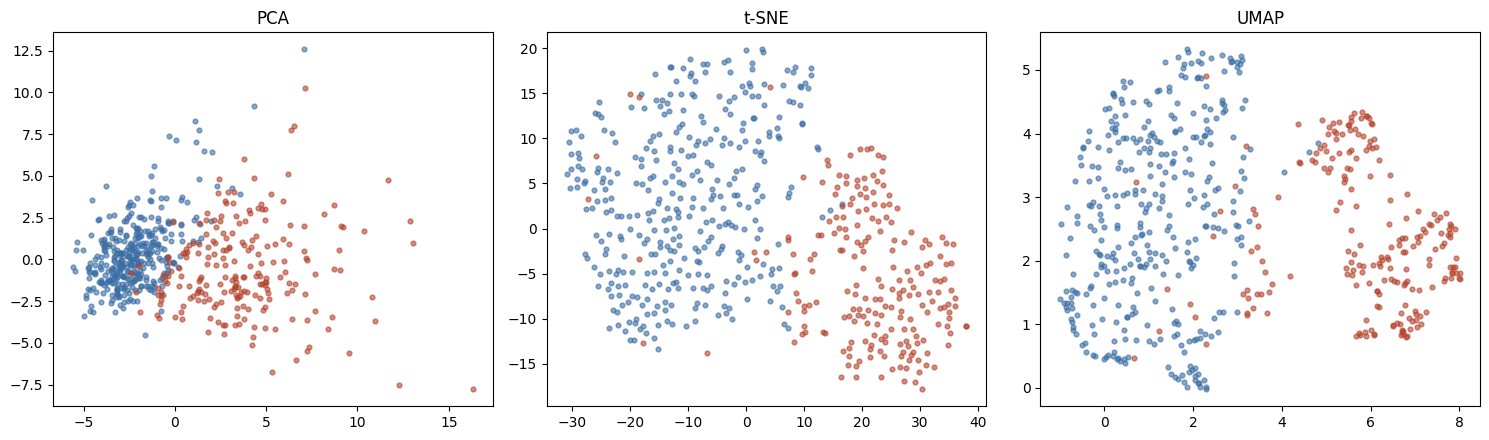

In [7]:
# TODO 1: standardize
X_scaled = StandardScaler().fit_transform(X_raw)

# TODO 2: compute all three embeddings
pca_emb = PCA(n_components=2, random_state=0).fit_transform(X_scaled)
tsne_emb = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(X_scaled)
umap_emb = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, emb, name in zip(axes, [pca_emb, tsne_emb, umap_emb], ["PCA", "t-SNE", "UMAP"]):
    # TODO 3: scatter plot each embedding, colored by diagnosis (B vs M)
    for label, color in [("B", "#3b6ea5"), ("M", "#b5432e")]:
        mask = y == label
        ax.scatter(emb[mask, 0], emb[mask, 1], s=12, alpha=0.6, color=color, label=label)
    ax.set_title(name)

plt.tight_layout()
plt.show()

**Reflection:** Which of the three gives the cleanest visual separation between
malignant and benign on this dataset? Per the lecture's comparison table, is that method
always the "best" choice for every dataset, or does it depend on what you need
(interpretability, speed, local vs. global structure)?

_Your answer:_ t-SNE and UMAP give the clearest separation on this dataset, with tighter clusters than PCA. But that does not mean they are always better. PCA is faster, easier to interpret, deterministic, and better at preserving global structure. t-SNE and UMAP are more computationally expensive and depend on settings like perplexity or n_neighbors, while mainly preserving local structure. So the choice depends on whether we prioritize interpretability and speed or visual cluster separation.

## Task 6 — The Decision (No Code)

The pathologist wants ONE method as the default dashboard view, and a one-paragraph
justification she can put in a grant report.

**Reflection (final):** Write a 4–6 sentence recommendation. Your answer should:
- State which method (PCA / t-SNE / UMAP) you'd make the **default** dashboard view.
- Justify it using at least one specific idea from the lecture (e.g. PCA's
  interpretable linear axes vs. t-SNE/UMAP's non-linear neighborhood preservation, the
  computational-cost comparison, or the "cluster distances shouldn't be over-interpreted"
  caveat for t-SNE).
- Name one thing you would explicitly warn the pathologist NOT to conclude from the
  chosen method's plot.

_Your final recommendation here:_ I would make PCA the default dashboard view. Even though t-SNE gave tighter clusters, PCA is easier to interpret since PC1 roughly represents overall tumor size and shape. It is also faster and deterministic, so the results stay consistent after refreshing. However, I would clarify that patients appearing close together in the 2D plot are not necessarily clinically similar, since the plot only captures around 63% of the total variance and leaves out information from the other dimensions.